# Proyek Analisis Data: Bike Sharing Dataset (Capital Bikeshare, Washington D.C. 2011–2012)

- **Nama:** Nay
- **Dataset:** Bike Sharing Dataset (`day.csv` 731 hari, `hour.csv` 17.379 jam)
- **Tools:** Python, Pandas, Matplotlib, Seaborn, Streamlit

## Daftar Isi
1. Menentukan Pertanyaan Bisnis
2. Import Library
3. Data Wrangling (Gathering, Assessing, Cleaning)
4. Exploratory Data Analysis (EDA)
5. Visualization & Explanatory Analysis
6. Analisis Lanjutan (Manual Grouping & Binning)
7. Conclusion & Rekomendasi

## 1. Menentukan Pertanyaan Bisnis

**Konteks bisnis:** Operator bike sharing perlu memutuskan *kapan* dan *dalam kondisi apa* armada sepeda harus disiapkan. Salah alokasi berarti sepeda menganggur di jam sepi atau kehabisan di jam sibuk.

**Pertanyaan 1 (pola waktu):**
> Pada jam berapa rata-rata penyewaan sepeda mencapai puncak pada **hari kerja** dibandingkan **akhir pekan/hari libur**, dan berapa selisih rata-rata penyewaan per jam pada jam puncak tersebut selama periode **Januari 2011 – Desember 2012**?

| Unsur SMART | Penjelasan |
|---|---|
| Specific | Fokus pada pola jam (0–23) untuk dua tipe hari |
| Measurable | Rata-rata `cnt` per jam dan selisihnya (angka) |
| Action-oriented | Menentukan jam penempatan & rebalancing armada, serta jadwal perawatan di jam sepi |
| Relevant | Ketersediaan sepeda saat demand tertinggi adalah masalah inti operasional |
| Time-bound | Jan 2011 – Des 2012 |

**Pertanyaan 2 (faktor cuaca & musim):**
> Seberapa besar penurunan rata-rata penyewaan harian pada kondisi cuaca buruk (`weathersit` 2 dan 3) dibandingkan cuaca cerah (`weathersit` 1), dan musim mana yang memiliki rata-rata penyewaan harian tertinggi dan terendah sepanjang **2011–2012**?

| Unsur SMART | Penjelasan |
|---|---|
| Specific | Cuaca (3 kategori) dan musim (4 kategori) terhadap penyewaan harian |
| Measurable | Persentase penurunan rata-rata `cnt` harian vs cuaca cerah, rata-rata per musim |
| Action-oriented | Strategi promosi musiman, penjadwalan perawatan, dan antisipasi demand saat cuaca buruk |
| Relevant | Cuaca adalah faktor eksternal terbesar yang memengaruhi demand |
| Time-bound | 2011–2012 |

**Pertanyaan 3 (pertumbuhan, pelengkap):**
> Berapa pertumbuhan total penyewaan tahun 2012 dibandingkan 2011 (Year-over-Year), dan apakah pertumbuhan tersebut didorong oleh pengguna *registered* atau *casual*?

## 2. Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, GREY, ORANGE = "#1F77B4", "#B0B7C3", "#E8743B"

## 3. Data Wrangling

### 3.1 Gathering Data
Memuat `day.csv` (agregasi harian) dan `hour.csv` (agregasi per jam) ke dalam DataFrame.

In [2]:
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")
print("day_df :", day_df.shape)
print("hour_df:", hour_df.shape)
day_df.head()

day_df : (731, 16)
hour_df: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight Gathering Data**
- `day_df` berisi 731 hari (2 tahun penuh, 2012 kabisat) dan `hour_df` berisi 17.379 baris per jam.
- Kolom kategorikal (`season`, `weathersit`, `weekday`, dst.) masih berupa kode angka, sedangkan `temp`, `atemp`, `hum`, `windspeed` masih ternormalisasi. Keduanya perlu diterjemahkan agar mudah dibaca.

### 3.2 Assessing Data
Memeriksa tipe data, missing value, duplikasi, nilai tidak valid, konsistensi antar-tabel, kelengkapan waktu, dan outlier.

In [4]:
for name, df in [("day_df", day_df), ("hour_df", hour_df)]:
    print(f"===== {name} =====")
    df.info()
    print()

===== day_df =====
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB

===== hour_df =====
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Dat

In [5]:
print("Missing value day_df :", day_df.isna().sum().sum())
print("Missing value hour_df:", hour_df.isna().sum().sum())
print("Duplikat day_df :", day_df.duplicated().sum())
print("Duplikat hour_df:", hour_df.duplicated().sum())

Missing value day_df : 0
Missing value hour_df: 0
Duplikat day_df : 0
Duplikat hour_df: 0


In [6]:
day_df.describe().T

,count,mean,std,min,25%,50%,75%,max
instant,731.0,366.000000,211.165812,1.000000,183.500000,366.000000,548.500000,731.000000
season,731.0,2.496580,1.110807,1.000000,2.000000,3.000000,3.000000,4.000000
yr,731.0,0.500684,0.500342,0.000000,0.000000,1.000000,1.000000,1.000000
mnth,731.0,6.519836,3.451913,1.000000,4.000000,7.000000,10.000000,12.000000
holiday,731.0,0.028728,0.167155,0.000000,0.000000,0.000000,0.000000,1.000000
weekday,731.0,2.997264,2.004787,0.000000,1.000000,3.000000,5.000000,6.000000
workingday,731.0,0.683995,0.465233,0.000000,0.000000,1.000000,1.000000,1.000000
weathersit,731.0,1.395349,0.544894,1.000000,1.000000,1.000000,2.000000,3.000000
temp,731.0,0.495385,0.183051,0.059130,0.337083,0.498333,0.655417,0.861667
atemp,731.0,0.474354,0.162961,0.079070,0.337842,0.486733,0.608602,0.840896


In [7]:
# Invalid value: kelembapan = 0 (tidak masuk akal secara fisik di kota seperti D.C.)
print(day_df[day_df["hum"] == 0][["dteday", "hum", "cnt"]])
print(hour_df[hour_df["hum"] == 0]["dteday"].value_counts())

        dteday  hum  cnt
68  2011-03-10  0.0  623
dteday
2011-03-10    22
Name: count, dtype: int64


In [8]:
# Konsistensi: cnt harus = casual + registered, dan total harian harus sama dengan jumlah per jam
print("cnt != casual+registered (day) :", (day_df.cnt != day_df.casual + day_df.registered).sum())
print("cnt != casual+registered (hour):", (hour_df.cnt != hour_df.casual + hour_df.registered).sum())
daily_from_hour = hour_df.groupby("dteday")["cnt"].sum()
cmp = day_df.set_index("dteday")["cnt"].compare(daily_from_hour)
print("Hari yang total harian != jumlah per jam:", len(cmp))

cnt != casual+registered (day) : 0
cnt != casual+registered (hour): 0
Hari yang total harian != jumlah per jam: 0


In [9]:
# Kelengkapan waktu: 731 hari x 24 jam = 17.544 baris seharusnya
expected = pd.date_range("2011-01-01 00:00", "2012-12-31 23:00", freq="h")
hour_df["_ts"] = pd.to_datetime(hour_df["dteday"]) + pd.to_timedelta(hour_df["hr"], unit="h")
missing_ts = expected.difference(hour_df["_ts"])
print("Jam yang seharusnya ada :", len(expected))
print("Jam yang ada di hour_df :", len(hour_df))
print("Jam yang hilang         :", len(missing_ts))
print(pd.Series(missing_ts.hour).value_counts().sort_index().head(10).to_dict(), "<- distribusi jam hilang (0-9)")
hour_df.drop(columns="_ts", inplace=True)

Jam yang seharusnya ada : 17544
Jam yang ada di hour_df : 17379
Jam yang hilang         : 165
{0: 5, 1: 7, 2: 16, 3: 34, 4: 34, 5: 14, 6: 6, 7: 4, 8: 4, 9: 4} <- distribusi jam hilang (0-9)


In [10]:
# Outlier harian (metode IQR) dan hari dengan penyewaan terendah
q1, q3 = day_df["cnt"].quantile([0.25, 0.75])
iqr = q3 - q1
print("Batas bawah IQR:", q1 - 1.5 * iqr, "| Batas atas IQR:", q3 + 1.5 * iqr)
print("Outlier harian:", ((day_df.cnt < q1 - 1.5*iqr) | (day_df.cnt > q3 + 1.5*iqr)).sum())
print(day_df.nsmallest(3, "cnt")[["dteday", "cnt", "weathersit"]])
print("Outlier windspeed (IQR) :", end=" ")
w1, w3 = day_df.windspeed.quantile([.25, .75]); print(((day_df.windspeed > w3 + 1.5*(w3-w1))).sum())

Batas bawah IQR: -1054.0 | Batas atas IQR: 10162.0
Outlier harian: 0
         dteday  cnt  weathersit
667  2012-10-29   22           3
26   2011-01-27  431           1
725  2012-12-26  441           3
Outlier windspeed (IQR) : 13


**Hasil Assessing Data**

| No | Masalah | Temuan | Rencana Tindakan (Cleaning) |
|---|---|---|---|
| 1 | **Inaccurate/Invalid value** | `hum = 0` pada 2011-03-10 (1 hari di `day_df`, 1 hari penuh di `hour_df`) | Ubah menjadi NaN lalu isi dengan interpolasi linear |
| 2 | **Wrong data type** | `dteday` bertipe string/object | Konversi ke `datetime64` |
| 3 | **Inconsistent value (encoding)** | `season`, `yr`, `mnth`, `weekday`, `weathersit` berupa kode angka; `temp`, `atemp`, `hum`, `windspeed` ternormalisasi | Mapping ke label teks; denormalisasi ke satuan asli |
| 4 | **Missing records (kelengkapan waktu)** | `hour_df` kehilangan 165 jam dari 17.544 (terutama dini hari: tidak ada transaksi pada jam tersebut) | Tidak diimputasi, karena baris yang hilang mewakili jam tanpa transaksi; dicatat sebagai keterbatasan |
| 5 | **Outlier/anomali** | Penyewaan harian hanya 22 pada 2012-10-29 (Hurricane Sandy), jauh di bawah rata-rata ~4.504 (tidak terdeteksi IQR karena batas bawah negatif, tetapi jelas anomali); 13 hari outlier `windspeed` menurut IQR | **Dipertahankan** karena valid dan merupakan event nyata |
| 6 | Missing value & duplikat | Tidak ada | Tidak perlu tindakan |
| 7 | Konsistensi antar-tabel | `cnt = casual + registered` dan total harian = jumlah per jam | Aman |

### 3.3 Cleaning Data

**a. Konversi tipe data tanggal**

In [11]:
for df in (day_df, hour_df):
    df["dteday"] = pd.to_datetime(df["dteday"])
print(day_df["dteday"].dtype, hour_df["dteday"].dtype)

datetime64[us] datetime64[us]


**b. Menangani invalid value `hum = 0`** (diganti NaN lalu diinterpolasi berdasarkan tetangga waktu)

In [12]:
day_df = day_df.sort_values("dteday").reset_index(drop=True)
hour_df = hour_df.sort_values(["dteday", "hr"]).reset_index(drop=True)

for df in (day_df, hour_df):
    df["hum"] = df["hum"].replace(0, np.nan)
    df["hum"] = df["hum"].interpolate(method="linear", limit_direction="both")

print("hum min day :", day_df["hum"].min(), "| hum min hour:", hour_df["hum"].min())
print(day_df.loc[day_df.dteday == "2011-03-10", ["dteday", "hum"]])

hum min day : 0.187917 | hum min hour: 0.08
       dteday       hum
68 2011-03-10  0.712491


**c. Mapping kode ke label & denormalisasi variabel cuaca**

In [13]:
season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
year_map = {0: 2011, 1: 2012}
weather_map = {1: "Cerah", 2: "Berkabut/Mendung", 3: "Hujan/Salju Ringan", 4: "Hujan/Salju Lebat"}
weekday_map = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}
month_map = {1:"Jan",2:"Feb",3:"Mar",4:"Apr",5:"Mei",6:"Jun",7:"Jul",8:"Agu",9:"Sep",10:"Okt",11:"Nov",12:"Des"}

for df in (day_df, hour_df):
    df["season"] = df["season"].map(season_map)
    df["year"] = df["yr"].map(year_map)
    df["month"] = df["mnth"].map(month_map)
    df["weather"] = df["weathersit"].map(weather_map)
    df["weekday_name"] = df["weekday"].map(weekday_map)
    df["day_type"] = np.where(df["workingday"] == 1, "Hari Kerja", "Akhir Pekan/Libur")
    df["temp_c"] = (df["temp"] * 41).round(1)
    df["atemp_c"] = (df["atemp"] * 50).round(1)
    df["hum_pct"] = (df["hum"] * 100).round(1)
    df["wind_kmh"] = (df["windspeed"] * 67).round(1)

day_df[["dteday","season","year","weather","day_type","temp_c","hum_pct","wind_kmh","cnt"]].head()

,dteday,season,year,weather,day_type,temp_c,hum_pct,wind_kmh,cnt
0,2011-01-01,Spring,2011,Berkabut/Mendung,Akhir Pekan/Libur,14.1,80.6,10.7,985
1,2011-01-02,Spring,2011,Berkabut/Mendung,Akhir Pekan/Libur,14.9,69.6,16.7,801
2,2011-01-03,Spring,2011,Cerah,Hari Kerja,8.1,43.7,16.6,1349
3,2011-01-04,Spring,2011,Cerah,Hari Kerja,8.2,59.0,10.7,1562
4,2011-01-05,Spring,2011,Cerah,Hari Kerja,9.3,43.7,12.5,1600


In [14]:
# Validasi akhir
print("Missing :", day_df.isna().sum().sum(), hour_df.isna().sum().sum())
print("Rentang suhu (C):", day_df.temp_c.min(), "-", day_df.temp_c.max())
print("Rentang humidity (%):", day_df.hum_pct.min(), "-", day_df.hum_pct.max())
print(hour_df["weather"].value_counts())

Missing : 0 0
Rentang suhu (C): 2.4 - 35.3
Rentang humidity (%): 18.8 - 97.2
weather
Cerah                 11413
Berkabut/Mendung       4544
Hujan/Salju Ringan     1419
Hujan/Salju Lebat         3
Name: count, dtype: int64


**Insight Cleaning Data**
- Satu nilai kelembapan tidak valid (0%) pada 10 Maret 2011 sudah diperbaiki dengan interpolasi, sehingga tidak merusak korelasi/rata-rata.
- Semua variabel kini terbaca dalam satuan dan label yang bermakna (suhu 2–35 °C, humidity 0–100%, dst.).
- Kategori cuaca 4 (lebat) hanya berjumlah 3 jam pada data per jam dan tidak ada di data harian, sehingga **analisis cuaca difokuskan pada kategori 1–3**.
- Anomali Hurricane Sandy (22 sewa pada 29 Okt 2012) dipertahankan karena merupakan kejadian riil yang justru informatif.

## 4. Exploratory Data Analysis (EDA)

### 4.1 Ringkasan Statistik

In [15]:
day_df[["cnt","casual","registered","temp_c","hum_pct","wind_kmh"]].describe().round(1)

,cnt,casual,registered,temp_c,hum_pct,wind_kmh
count,731.0,731.0,731.0,731.0,731.0,731.0
mean,4504.3,848.2,3656.2,20.3,62.9,12.8
std,1937.2,686.6,1560.3,7.5,14.1,5.2
min,22.0,2.0,20.0,2.4,18.8,1.5
25%,3152.0,315.5,2497.0,13.8,52.1,9.0
50%,4548.0,713.0,3662.0,20.4,62.7,12.1
75%,5956.0,1096.0,4776.5,26.9,73.0,15.6
max,8714.0,3410.0,6946.0,35.3,97.2,34.0


### 4.2 EDA Pertanyaan 1: Pola penyewaan per jam, hari kerja vs akhir pekan/libur

In [16]:
hourly_pattern = hour_df.pivot_table(index="hr", columns="day_type", values="cnt", aggfunc="mean").round(1)
hourly_pattern["selisih"] = (hourly_pattern["Hari Kerja"] - hourly_pattern["Akhir Pekan/Libur"]).round(1)
hourly_pattern

day_type,Akhir Pekan/Libur,Hari Kerja,selisih
hr,,,
0,90.8,36.8,-54.0
1,69.5,16.6,-52.9
2,53.2,8.7,-44.5
3,25.8,4.9,-20.9
4,8.3,5.4,-2.9
5,8.7,24.9,16.2
6,18.7,102.5,83.8
7,43.4,290.6,247.2
8,105.7,477.0,371.3


In [17]:
for t in ["Hari Kerja", "Akhir Pekan/Libur"]:
    s = hourly_pattern[t]
    top = s.nlargest(3)
    print(f"{t:18s} | puncak: jam {top.index[0]:02d}:00 = {top.iloc[0]:.0f} | 3 teratas: {dict(top.round(0))}")

wd = hourly_pattern["Hari Kerja"]; we = hourly_pattern["Akhir Pekan/Libur"]
print()
print(f"Jam 08:00 -> kerja {wd[8]:.0f} vs libur {we[8]:.0f} (kerja {wd[8]/we[8]-1:+.0%})")
print(f"Jam 17:00 -> kerja {wd[17]:.0f} vs libur {we[17]:.0f} (kerja {wd[17]/we[17]-1:+.0%})")
print(f"Jam 13:00 -> kerja {wd[13]:.0f} vs libur {we[13]:.0f} (kerja {wd[13]/we[13]-1:+.0%})")

Hari Kerja         | puncak: jam 17:00 = 525 | 3 teratas: {17: np.float64(525.0), 18: np.float64(492.0), 8: np.float64(477.0)}


Akhir Pekan/Libur  | puncak: jam 13:00 = 373 | 3 teratas: {13: np.float64(373.0), 12: np.float64(366.0), 14: np.float64(365.0)}

Jam 08:00 -> kerja 477 vs libur 106 (kerja +351%)
Jam 17:00 -> kerja 525 vs libur 324 (kerja +62%)
Jam 13:00 -> kerja 198 vs libur 373 (kerja -47%)


In [18]:
# Komposisi pengguna per tipe hari
hour_df.groupby("day_type")[["casual","registered"]].mean().assign(
    share_registered=lambda d: (d.registered/(d.casual+d.registered)*100).round(1)).round(1)

,casual,registered,share_registered
day_type,,,
Akhir Pekan/Libur,57.4,124.0,68.3
Hari Kerja,25.6,167.6,86.8


### 4.3 EDA Pertanyaan 2: Pengaruh cuaca dan musim terhadap penyewaan harian

In [19]:
weather_stat = day_df.groupby("weather")["cnt"].agg(["count","mean","median"]).round(0)
base = weather_stat.loc["Cerah","mean"]
weather_stat["selisih_vs_cerah_%"] = ((weather_stat["mean"]/base - 1)*100).round(1)
weather_stat

,count,mean,median,selisih_vs_cerah_%
weather,,,,
Berkabut/Mendung,247,4036.0,4040.0,-17.2
Cerah,463,4877.0,4844.0,0.0
Hujan/Salju Ringan,21,1803.0,1817.0,-63.0


In [20]:
season_stat = day_df.groupby("season")["cnt"].agg(["mean","median","min","max"]).round(0).loc[["Spring","Summer","Fall","Winter"]]
season_stat["selisih_vs_tertinggi_%"] = ((season_stat["mean"]/season_stat["mean"].max()-1)*100).round(1)
season_stat

,mean,median,min,max,selisih_vs_tertinggi_%
season,,,,,
Spring,2604.0,2209.0,431,7836,-53.9
Summer,4992.0,4942.0,795,8362,-11.6
Fall,5644.0,5354.0,1115,8714,0.0
Winter,4728.0,4634.0,22,8555,-16.2


In [21]:
day_df[["cnt","temp_c","atemp_c","hum_pct","wind_kmh"]].corr().round(2)["cnt"]

cnt         1.00
temp_c      0.63
atemp_c     0.63
hum_pct    -0.12
wind_kmh   -0.23
Name: cnt, dtype: float64

### 4.4 EDA Pertanyaan 3: Pertumbuhan 2012 vs 2011

In [22]:
yoy = day_df.groupby("year")[["casual","registered","cnt"]].sum()
yoy.loc["Pertumbuhan YoY (%)"] = ((yoy.loc[2012]/yoy.loc[2011]-1)*100).round(1)
yoy

,casual,registered,cnt
year,,,
2011,247252.0,995851.0,1243103.0
2012,372765.0,1676811.0,2049576.0
Pertumbuhan YoY (%),50.8,68.4,64.9


In [23]:
monthly = day_df.pivot_table(index="mnth", columns="year", values="cnt", aggfunc="sum")
monthly["growth_%"] = ((monthly[2012]/monthly[2011]-1)*100).round(0)
monthly

year,2011,2012,growth_%
mnth,,,
1,38189,96744,153.0
2,48215,103137,114.0
3,64045,164875,157.0
4,94870,174224,84.0
5,135821,195865,44.0
6,143512,202830,41.0
7,141341,203607,44.0
8,136691,214503,57.0
9,127418,218573,72.0


**Insight EDA**
- Pada hari kerja, pola **dua puncak** jelas (komuter), sedangkan akhir pekan membentuk **satu puncak** lebar di siang hari.
- Cuaca dan suhu adalah penentu demand yang kuat: korelasi suhu dengan penyewaan sekitar +0,63, sedangkan kelembapan dan kecepatan angin berkorelasi negatif lemah.
- Total penyewaan melonjak sekitar 65% dari 2011 ke 2012 (registered +68%, casual +51%), dan lonjakan terbesar terjadi pada Januari–Maret (>110%).

## 5. Visualization & Explanatory Analysis

### Visualisasi 1: Pola rata-rata penyewaan per jam (menjawab Pertanyaan 1)

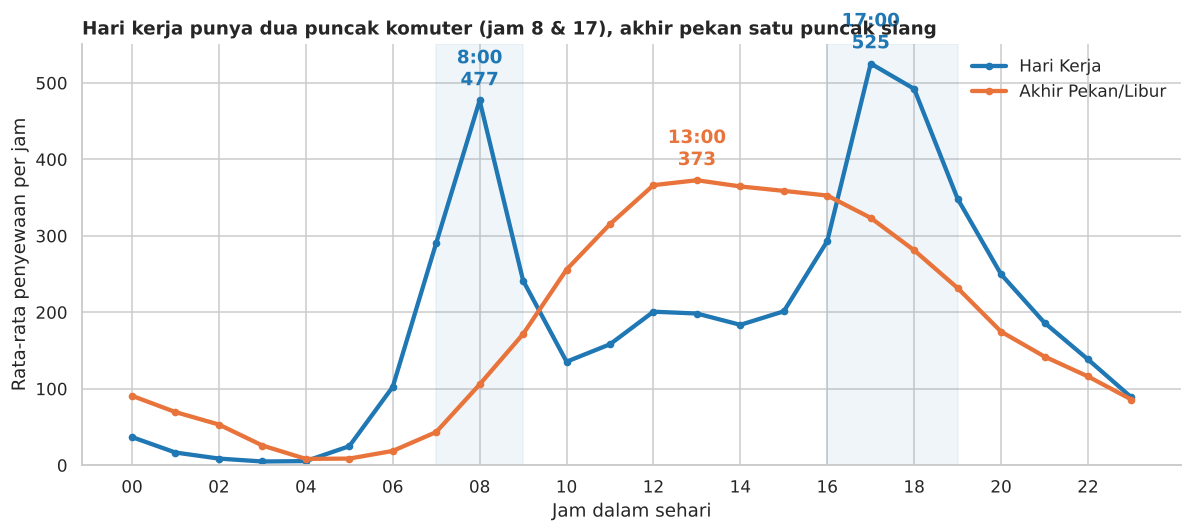

In [24]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(hourly_pattern.index, hourly_pattern["Hari Kerja"], color=BLUE, lw=2.8, marker="o", ms=4, label="Hari Kerja")
ax.plot(hourly_pattern.index, hourly_pattern["Akhir Pekan/Libur"], color=ORANGE, lw=2.8, marker="o", ms=4, label="Akhir Pekan/Libur")

wd, we = hourly_pattern["Hari Kerja"], hourly_pattern["Akhir Pekan/Libur"]
for h_ in [8, 17]:
    ax.annotate(f"{h_}:00\n{wd[h_]:.0f}", (h_, wd[h_]), textcoords="offset points", xytext=(0, 10), ha="center", color=BLUE, fontweight="bold")
ax.annotate(f"{we.idxmax()}:00\n{we.max():.0f}", (we.idxmax(), we.max()), textcoords="offset points", xytext=(0, 10), ha="center", color=ORANGE, fontweight="bold")

ax.axvspan(7, 9, color=BLUE, alpha=0.07); ax.axvspan(16, 19, color=BLUE, alpha=0.07)
ax.set_xticks(range(0, 24, 2)); ax.set_xticklabels([f"{h_:02d}" for h_ in range(0, 24, 2)])
ax.set_ylim(0, None)
ax.set_xlabel("Jam dalam sehari"); ax.set_ylabel("Rata-rata penyewaan per jam")
ax.set_title("Hari kerja punya dua puncak komuter (jam 8 & 17), akhir pekan satu puncak siang", loc="left", fontweight="bold")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Insight Visualisasi 1:** Pada hari kerja puncak tertinggi terjadi pukul **17:00** (~525 sewa/jam) dan puncak kedua pukul **08:00** (~478 sewa/jam), pola khas komuter. Pada akhir pekan/libur, demand membentuk satu puncak landai dengan titik tertinggi **13:00** (~373 sewa/jam) dan bertahan tinggi pada 11:00–15:00. Selisih di jam puncak komuter sangat besar: pukul 08:00 hari kerja unggul **+371 sewa/jam** (477 vs 106, sekitar 4,5x lipat) dan pukul 17:00 unggul **+202 sewa/jam** (525 vs 324). Sebaliknya, pada siang hari (10:00–15:00) dan dini hari, akhir pekan justru lebih tinggi. Artinya kebutuhan armada **bergeser mengikuti jenis hari**, bukan hanya jam.

### Visualisasi 2: Dampak cuaca & musim terhadap penyewaan harian (menjawab Pertanyaan 2)

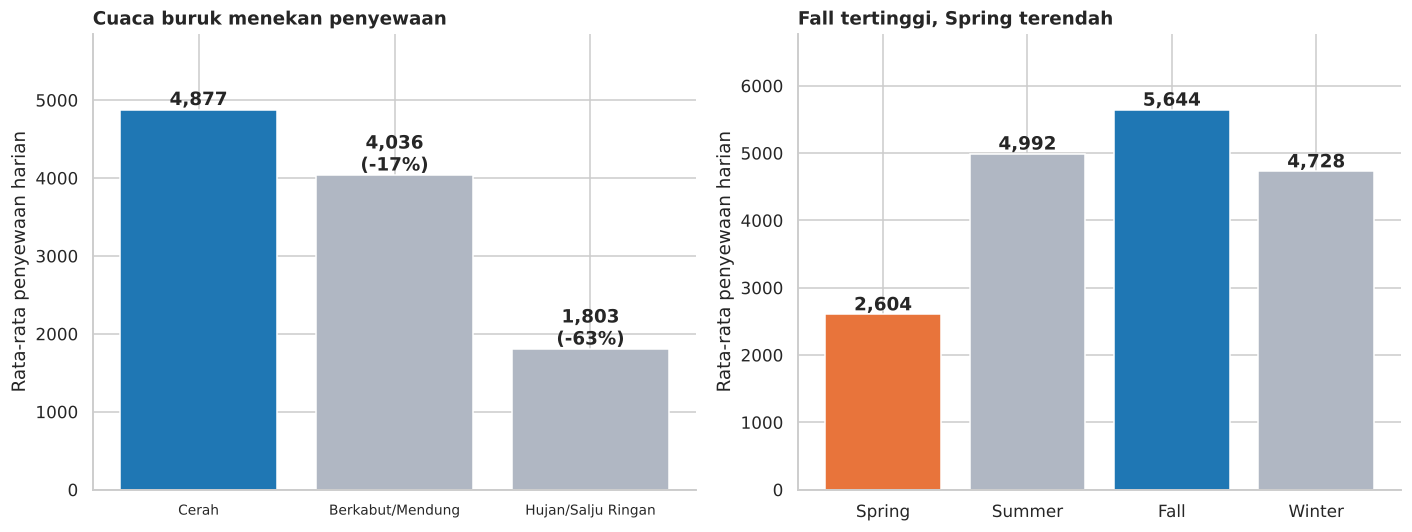

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# (a) Cuaca
order_w = ["Cerah", "Berkabut/Mendung", "Hujan/Salju Ringan"]
w = day_df.groupby("weather")["cnt"].mean().loc[order_w]
cols_w = [BLUE if k == "Cerah" else GREY for k in order_w]
bars = axes[0].bar(order_w, w.values, color=cols_w)
for b, k in zip(bars, order_w):
    pct = "" if k == "Cerah" else f"\n({w[k]/w['Cerah']-1:+.0%})"
    axes[0].text(b.get_x()+b.get_width()/2, b.get_height()+60, f"{b.get_height():,.0f}{pct}", ha="center", fontweight="bold")
axes[0].set_ylim(0, w.max()*1.2); axes[0].set_ylabel("Rata-rata penyewaan harian")
axes[0].set_title("Cuaca buruk menekan penyewaan", loc="left", fontweight="bold")
axes[0].tick_params(axis="x", labelsize=9)

# (b) Musim
order_s = ["Spring", "Summer", "Fall", "Winter"]
s = day_df.groupby("season")["cnt"].mean().loc[order_s]
cols_s = [BLUE if k == s.idxmax() else (ORANGE if k == s.idxmin() else GREY) for k in order_s]
bars = axes[1].bar(order_s, s.values, color=cols_s)
for b in bars:
    axes[1].text(b.get_x()+b.get_width()/2, b.get_height()+60, f"{b.get_height():,.0f}", ha="center", fontweight="bold")
axes[1].set_ylim(0, s.max()*1.2); axes[1].set_ylabel("Rata-rata penyewaan harian")
axes[1].set_title("Fall tertinggi, Spring terendah", loc="left", fontweight="bold")

plt.tight_layout(); plt.show()

**Insight Visualisasi 2:**
- Dibanding hari cerah (~4.877/hari), cuaca berkabut/mendung turun sekitar **17%** (~4.036/hari) dan hujan/salju ringan turun sekitar **63%** (~1.803/hari).
- Musim **Fall** adalah yang tertinggi (~5.644/hari) dan **Spring** yang terendah (~2.604/hari, sekitar 54% lebih rendah dari Fall). Catatan: pada dataset ini label `season=1` adalah *springer* (awal tahun), yang bertepatan dengan periode awal sistem sehingga juga dipengaruhi oleh pertumbuhan.

### Visualisasi 3: Pertumbuhan bulanan 2011 vs 2012 (menjawab Pertanyaan 3)

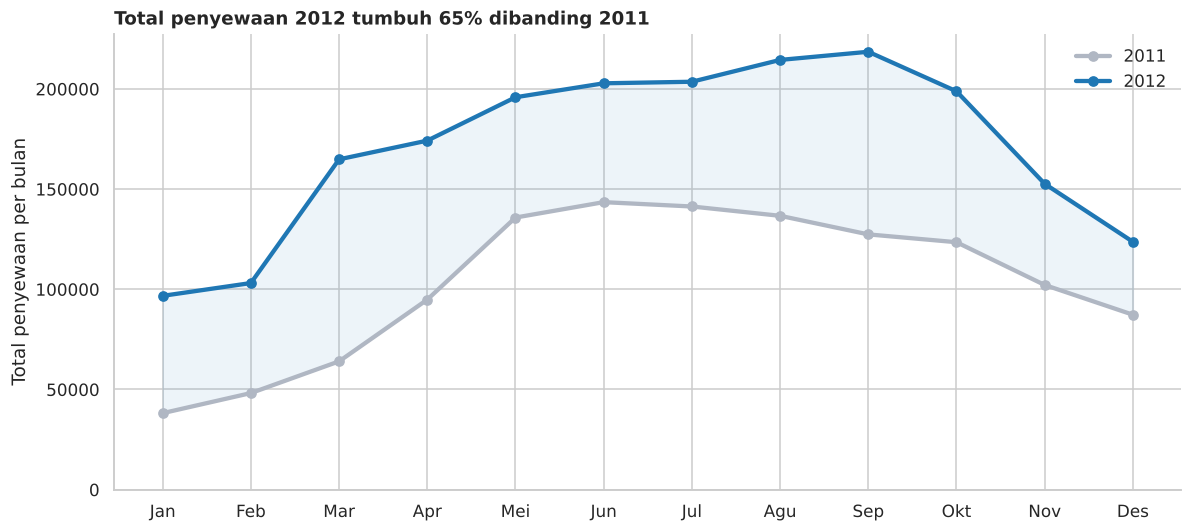

In [26]:
fig, ax = plt.subplots(figsize=(11, 5))
m = day_df.pivot_table(index="mnth", columns="year", values="cnt", aggfunc="sum")
labels = [month_map[i] for i in m.index]
ax.plot(labels, m[2011], color=GREY, lw=2.8, marker="o", label="2011")
ax.plot(labels, m[2012], color=BLUE, lw=2.8, marker="o", label="2012")
ax.fill_between(labels, m[2011], m[2012], color=BLUE, alpha=0.08)
ax.set_ylim(0, None); ax.set_ylabel("Total penyewaan per bulan")
g = yoy.loc["Pertumbuhan YoY (%)", "cnt"]
ax.set_title(f"Total penyewaan 2012 tumbuh {g:.0f}% dibanding 2011", loc="left", fontweight="bold")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Insight Visualisasi 3:** Total penyewaan tumbuh **~65%** dari 2011 ke 2012. Pertumbuhan didorong lebih kuat oleh pengguna *registered* (**+68%**) dibanding *casual* (**+51%**). Lonjakan terbesar terjadi pada Januari–Maret (+114% hingga +157%), sedangkan pola musiman (puncak Jun–Sep) tetap sama pada kedua tahun.

## 6. Analisis Lanjutan: Manual Grouping & Binning (tanpa Machine Learning)

**Tujuan:** Dataset ini tidak memiliki identitas pelanggan atau koordinat lokasi, sehingga RFM dan geospatial analysis **tidak relevan**. Teknik yang sesuai adalah **Manual Grouping** (segmen waktu dalam sehari) dan **Binning** (kategori suhu dan kategori tingkat demand harian) untuk mengubah angka kontinu menjadi segmen yang bisa langsung dipakai operasional.

### 6.1 Manual Grouping: Segmen waktu dalam sehari

In [27]:
def time_segment(h):
    if 5 <= h <= 6:   return "1. Pagi Awal (05-06)"
    if 7 <= h <= 9:   return "2. Puncak Pagi (07-09)"
    if 10 <= h <= 15: return "3. Siang (10-15)"
    if 16 <= h <= 19: return "4. Puncak Sore (16-19)"
    if 20 <= h <= 23: return "5. Malam (20-23)"
    return "6. Dini Hari (00-04)"

hour_df["time_segment"] = hour_df["hr"].apply(time_segment)
seg = hour_df.pivot_table(index="time_segment", columns="day_type", values="cnt", aggfunc="mean").round(0)
seg

day_type,Akhir Pekan/Libur,Hari Kerja
time_segment,,
1. Pagi Awal (05-06),14.0,64.0
2. Puncak Pagi (07-09),107.0,336.0
3. Siang (10-15),339.0,180.0
4. Puncak Sore (16-19),297.0,415.0
5. Malam (20-23),130.0,166.0
6. Dini Hari (00-04),50.0,15.0


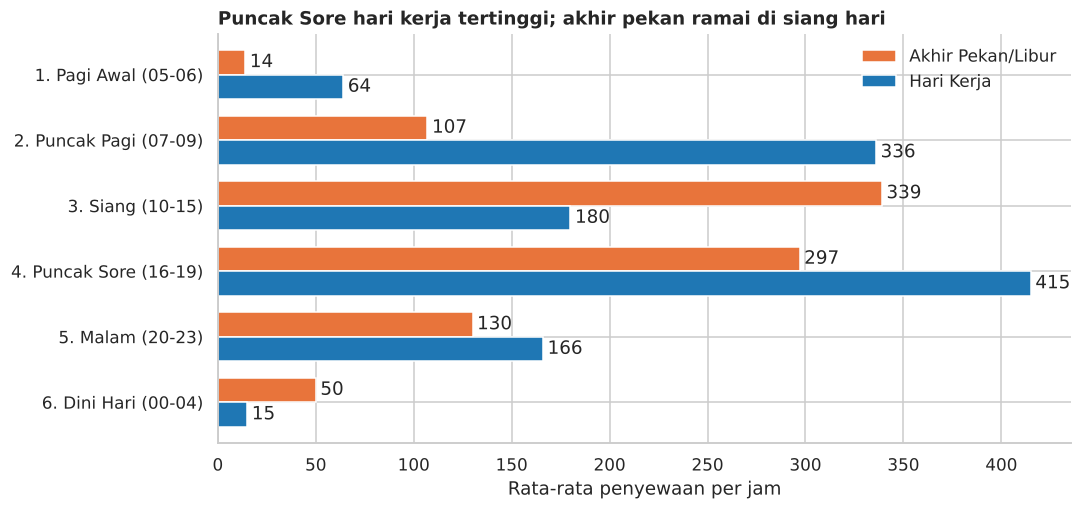

In [28]:
fig, ax = plt.subplots(figsize=(10, 4.8))
seg.plot(kind="barh", ax=ax, color=[ORANGE, BLUE], width=0.75)
ax.invert_yaxis(); ax.set_xlabel("Rata-rata penyewaan per jam"); ax.set_ylabel("")
for c in ax.containers: ax.bar_label(c, fmt="%.0f", padding=3)
ax.set_title("Puncak Sore hari kerja tertinggi; akhir pekan ramai di siang hari", loc="left", fontweight="bold")
ax.legend(title="", frameon=False); plt.tight_layout(); plt.show()

### 6.2 Binning: Kategori suhu dan tingkat demand harian

In [29]:
day_df["temp_bin"] = pd.cut(day_df["temp_c"], bins=[0, 10, 20, 30, 40], labels=["Dingin (<10C)", "Sejuk (10-20C)", "Hangat (20-30C)", "Panas (>30C)"])
temp_stat = day_df.groupby("temp_bin", observed=True)["cnt"].agg(["count", "mean"]).round(0)
temp_stat

,count,mean
temp_bin,,
Dingin (<10C),60,1678.0
Sejuk (10-20C),299,3692.0
Hangat (20-30C),300,5662.0
Panas (>30C),72,5410.0


In [30]:
# Kategori demand harian berdasarkan kuartil (Low / Medium / High)
q = day_df["cnt"].quantile([0.33, 0.66]).values
day_df["demand_level"] = pd.cut(day_df["cnt"], bins=[0, q[0], q[1], day_df["cnt"].max()+1], labels=["Rendah", "Sedang", "Tinggi"])
print("Batas:", q.round(0))
ct = pd.crosstab(day_df["weather"], day_df["demand_level"], normalize="index").mul(100).round(1)
ct = ct.loc[["Cerah", "Berkabut/Mendung", "Hujan/Salju Ringan"], ["Rendah", "Sedang", "Tinggi"]]
ct

Batas: [3716. 5266.]


demand_level,Rendah,Sedang,Tinggi
weather,,,
Cerah,25.7,33.7,40.6
Berkabut/Mendung,41.7,33.6,24.7
Hujan/Salju Ringan,90.5,9.5,0.0


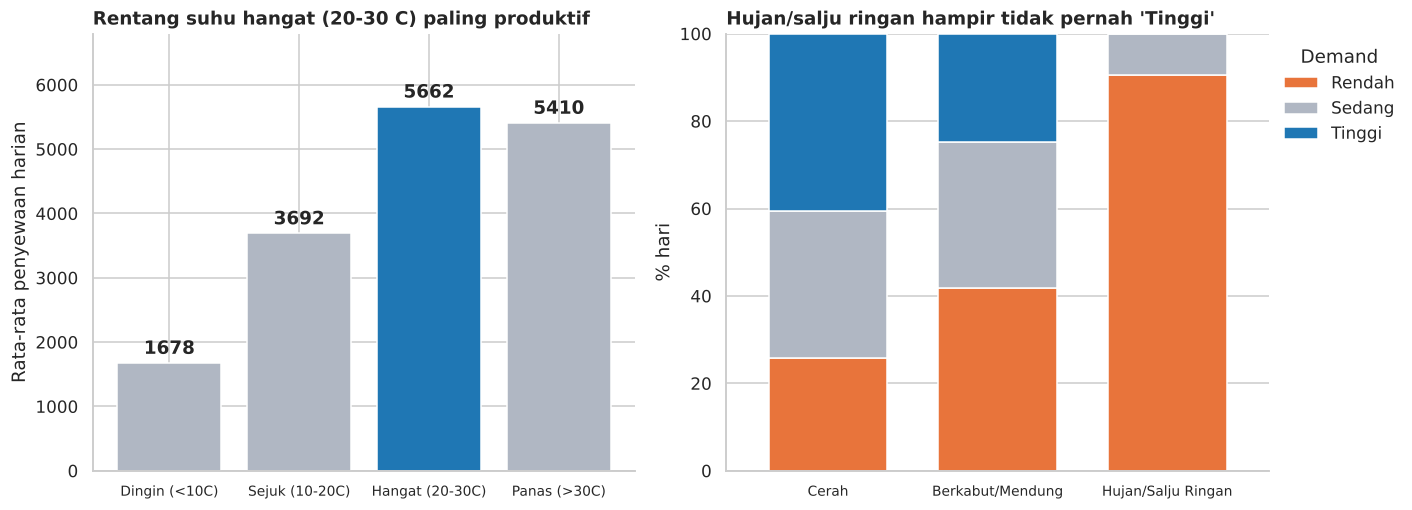

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
b = axes[0].bar(temp_stat.index.astype(str), temp_stat["mean"], color=[GREY, GREY, BLUE, GREY])
axes[0].bar_label(b, fmt="%.0f", padding=3, fontweight="bold")
axes[0].set_ylim(0, temp_stat["mean"].max()*1.2); axes[0].set_ylabel("Rata-rata penyewaan harian")
axes[0].set_title("Rentang suhu hangat (20-30 C) paling produktif", loc="left", fontweight="bold")
axes[0].tick_params(axis="x", labelsize=9)

ct.plot(kind="bar", stacked=True, ax=axes[1], color=[ORANGE, GREY, BLUE], width=0.7)
axes[1].set_ylabel("% hari"); axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=0, labelsize=9)
axes[1].set_title("Hujan/salju ringan hampir tidak pernah 'Tinggi'", loc="left", fontweight="bold")
axes[1].legend(title="Demand", frameon=False, bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

**Insight Analisis Lanjutan:**
- Segmen **Puncak Sore (16–19)** hari kerja memiliki demand per jam tertinggi (~415), diikuti **Siang akhir pekan** (~339) dan **Puncak Pagi hari kerja** (~336). Ketiganya menjadi prioritas ketersediaan armada.
- Segmen **Dini Hari (00–04)** konsisten sangat rendah sehingga paling cocok untuk jadwal perawatan dan rebalancing.
- Suhu hangat 20–30 °C memberi rata-rata penyewaan tertinggi; hari hujan/salju ringan hampir seluruhnya masuk kategori demand **Rendah**, sehingga bisa diantisipasi lewat prakiraan cuaca.

## 7. Conclusion & Rekomendasi

### Kesimpulan Pertanyaan 1 (pola jam)
Pada hari kerja, penyewaan memuncak pukul **17:00 (~525/jam)** dan **08:00 (~478/jam)**, mencerminkan pola komuter. Pada akhir pekan/libur, puncak hanya satu dan landai di sekitar **siang hari (puncak 13:00, ~373/jam)**. Selisih terbesar ada pada pukul 08:00 (hari kerja 477 vs akhir pekan 106 per jam, +371) dan pukul 17:00 (525 vs 324, +202), sedangkan pada siang hari 10:00–15:00 akhir pekan justru lebih tinggi sekitar 120–180 sewa/jam.

### Kesimpulan Pertanyaan 2 (cuaca & musim)
Dibanding cuaca cerah, penyewaan harian turun sekitar **17%** saat berkabut/mendung dan sekitar **63%** saat hujan/salju ringan. **Fall** adalah musim dengan rata-rata tertinggi (~5.644/hari), sedangkan **Spring** terendah (~2.604/hari).

### Kesimpulan Pertanyaan 3 (pertumbuhan)
Total penyewaan 2012 tumbuh sekitar **65%** dibanding 2011, didorong terutama oleh pengguna registered (+68% vs casual +51%), dengan pola musiman yang tetap sama di kedua tahun.

### Rekomendasi Action Item
1. **Rebalancing berbasis jam & tipe hari:** pastikan stok sepeda penuh di stasiun area permukiman sebelum 07:00 dan di area perkantoran sebelum 16:00 pada hari kerja; untuk akhir pekan geser fokus ke area rekreasi siang hari.
2. **Jadwalkan perawatan armada pada 00:00–04:00**, saat demand paling rendah, agar tidak mengganggu layanan.
3. **Integrasikan prakiraan cuaca** ke perencanaan harian: saat prakiraan hujan/salju, kurangi armada aktif (demand rata-rata turun ~63%) dan alihkan ke perawatan; saat cerah dan hangat (20–30 °C), siapkan kapasitas maksimum.
4. **Promosi musiman:** berikan diskon/paket pada musim demand rendah (Spring) dan siapkan kapasitas ekstra saat Summer–Fall.

### Keterbatasan
Data tidak memuat lokasi stasiun atau identitas pelanggan sehingga rekomendasi bersifat tingkat sistem. Terdapat 165 jam tanpa catatan pada data per jam (tidak diimputasi).

## Menyimpan Data Bersih untuk Dashboard

In [32]:
hour_df.to_csv("dashboard/main_data.csv", index=False)
day_df.to_csv("dashboard/day_data.csv", index=False)
print(hour_df.shape, day_df.shape)

(17379, 27) (731, 27)
